In [ ]:
pip install xgboost

In [ ]:
# =============================
# Imports
# =============================
import numpy as np
import pandas as pd
import xgboost as xgb

from sklearn.model_selection import KFold, GridSearchCV
from sklearn.preprocessing import StandardScaler, OrdinalEncoder
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
from sklearn.multioutput import MultiOutputRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import Lasso


In [ ]:
# =============================
# Load Data
# =============================
df = pd.read_csv('/content/data_pair_full.csv')
df = df.loc[:, ~df.columns.str.contains('^Unnamed')]

# =============================
# Preprocessing
# =============================
replacement_dict = {
    3: 2, 4: 2,
    5: 3, 6: 4,
    7: 5, 8: 6,
    9: 8, 10: 7
}

df['side_effect_1'] = df['side_effect_1'].replace(replacement_dict)
df['side_effect_2'] = df['side_effect_2'].replace(replacement_dict)

df = df[(df['side_effect_1'] != 0) & (df['side_effect_2'] != 0)]

In [ ]:
df.head(10)

,side,Contact_pt,Voltage_1,side_effect_1,Voltage_2,side_effect_2,Medio_lateral_X,AP_Y,supro_inferior_Z,Distance
0,1,3c,6.5,6.0,6.5,7.0,1.43,1.44,-0.04,2.03
1,1,4,6.0,6.0,6.0,7.0,1.05,3.43,0.84,3.69
2,2,2,5.0,6.0,5.0,7.0,-0.72,-1.04,-1.61,2.05
3,1,1,3.5,1.0,5.0,3.0,0.11,-2.33,-2.98,3.78
4,1,2,6.5,4.0,7.0,7.0,-0.12,-1.28,-1.31,1.84
5,1,2a,6.0,5.0,6.5,4.0,0.07,-0.72,-1.69,1.84
6,1,2b,5.0,3.0,5.5,4.0,-0.72,-1.30,-1.43,2.07
7,1,2c,4.5,1.0,5.5,7.0,0.19,-1.68,-1.03,1.98
8,1,3,5.5,7.0,5.5,5.0,-0.41,-0.20,0.19,0.49
9,1,3a,6.5,4.0,7.0,7.0,-0.05,0.21,-0.03,0.21


In [ ]:
print(df['Contact_pt'].dtype)
print(type(df['Contact_pt'][0]))
print(df['Contact_pt'].unique())

object
<class 'str'>
['3c' '4' '2' '1' '2a' '2b' '2c' '3' '3a' '3b' nan]


In [ ]:
df.isna().sum()

,0
side,35
Contact_pt,37
Voltage_1,37
side_effect_1,39
Voltage_2,37
side_effect_2,39
Medio_lateral_X,21
AP_Y,22
supro_inferior_Z,19
Distance,2


In [ ]:
# =============================
# Feature Engineering
# =============================
df['side_effect_diff'] = np.abs(df['side_effect_1'] - df['side_effect_2'])
df['voltage_diff'] = df['Voltage_1'] - df['Voltage_2']
df['voltage_interaction'] = df['Voltage_1'] * df['Voltage_2']
df['side_effect_interaction'] = df['side_effect_1'] * df['side_effect_2']

features = [
    'side', 'Contact_pt', 'Voltage_1', 'side_effect_1',
    'Voltage_2', 'side_effect_2',
    'side_effect_diff', 'voltage_diff',
    'voltage_interaction', 'side_effect_interaction'
]

target_cols = ['Medio_lateral_X', 'AP_Y', 'supro_inferior_Z']

data = df[features + target_cols].dropna()


In [ ]:
data.isna().sum()

,0
side,0
Contact_pt,0
Voltage_1,0
side_effect_1,0
Voltage_2,0
side_effect_2,0
side_effect_diff,0
voltage_diff,0
voltage_interaction,0
side_effect_interaction,0


In [ ]:
replacement_dict = {
    '1': 1, '2':2 ,
    '2a': 3, '2b': 4,
    '2c': 5, '3': 6,
    '3a': 7, '3b': 8,
    '3c': 9, '4': 10
}


In [ ]:
data['Contact_pt'] = data['Contact_pt'].replace(replacement_dict)


/tmp/ipykernel_7983/349812689.py:1: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  data['Contact_pt'] = data['Contact_pt'].replace(replacement_dict)


In [ ]:
data['Contact_pt'] = pd.to_numeric(data['Contact_pt'])

In [ ]:
X = data[features]
y = data[target_cols]


In [ ]:
X = data[features].apply(pd.to_numeric)
y = data[target_cols]

In [ ]:
# =============================
# Outer CV
# =============================
outer_kf = KFold(n_splits=10, shuffle=True, random_state=42)

# =============================
# Results
# =============================
results = {
    "Lasso": {"r2": [], "mae": [], "rmse": [], "mae_axes": [], "rmse_axes": [], "euc": []},
    "RF": {"r2": [], "mae": [], "rmse": [], "mae_axes": [], "rmse_axes": [], "euc": []},
    "XGB": {"r2": [], "mae": [], "rmse": [], "mae_axes": [], "rmse_axes": [], "euc": []}
}


In [ ]:
# =============================
# Metric Function
# =============================
def compute(y_true, y_pred):
    r2 = r2_score(y_true, y_pred)
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))

    mae_axes = mean_absolute_error(y_true, y_pred, multioutput='raw_values')
    rmse_axes = np.sqrt(mean_squared_error(y_true, y_pred, multioutput='raw_values'))

    euc = np.mean(np.linalg.norm(y_true.values - y_pred, axis=1))

    return r2, mae, rmse, mae_axes, rmse_axes, euc

In [ ]:
# =============================
# Models
# =============================
models = {
    "Lasso": Pipeline([

        ('model', MultiOutputRegressor(Lasso(max_iter=10000)))
    ]),

    "RF": Pipeline([
        ('model', MultiOutputRegressor(
            RandomForestRegressor(random_state=42, n_jobs=-1)
        ))
    ]),

    "XGB": Pipeline([
        ('model', MultiOutputRegressor(
            xgb.XGBRegressor(objective='reg:squarederror',
                             random_state=42, n_jobs=-1)
        ))
    ])
}

In [ ]:
# =============================
# Hyperparameters
# =============================
param_grids = {
    "Lasso": {
        'model__estimator__alpha': [0.001, 0.01, 0.1, 1]
    },
    "RF": {
        'model__estimator__n_estimators': [100, 200, 300, 500],
        'model__estimator__max_depth': [10, 12, None],
        'model__estimator__min_samples_leaf': [1, 2]
    },
    "XGB": {
        'model__estimator__n_estimators': [100, 200, 300, 500],
        'model__estimator__max_depth': [3, 4, 5, 6],
        'model__estimator__learning_rate': [0.03, 0.05, 0.1],
        'model__estimator__subsample': [0.8, 1.0],
        'model__estimator__colsample_bytree': [0.8, 1.0]
    }
}


In [ ]:
# =============================
# STORE FOR BLAND–ALTMAN .....
# =============================
all_true = []
all_preds = []
# =============================
# Nested CV
# =============================
for fold, (train_idx, test_idx) in enumerate(outer_kf.split(X)):

    print(f"\n OUTER FOLD {fold+1} ")

    X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
    y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

    for name in models:

        grid = GridSearchCV(
            models[name],
            param_grids[name],
            cv=KFold(n_splits=3, shuffle=True, random_state=42),
            scoring='neg_mean_squared_error',
            n_jobs=-1
        )

        grid.fit(X_train, y_train)
        preds = grid.best_estimator_.predict(X_test)


        if name == "XGB":
          all_true.append(y_test)
          all_preds.append(preds)

        r2, mae, rmse, mae_axes, rmse_axes, euc = compute(y_test, preds)

        results[name]["r2"].append(r2)
        results[name]["mae"].append(mae)
        results[name]["rmse"].append(rmse)
        results[name]["mae_axes"].append(mae_axes)
        results[name]["rmse_axes"].append(rmse_axes)
        results[name]["euc"].append(euc)



===== OUTER FOLD 1 =====

===== OUTER FOLD 2 =====

===== OUTER FOLD 3 =====

===== OUTER FOLD 4 =====

===== OUTER FOLD 5 =====

===== OUTER FOLD 6 =====

===== OUTER FOLD 7 =====

===== OUTER FOLD 8 =====

===== OUTER FOLD 9 =====

===== OUTER FOLD 10 =====


In [ ]:
# =============================
# Train FINAL model (best model = XGB)
# =============================
final_model = Pipeline([

    ('model', MultiOutputRegressor(
        xgb.XGBRegressor(
            objective='reg:squarederror',
            n_estimators=300,
            max_depth=4,
            learning_rate=0.05,
            subsample=0.8,
            colsample_bytree=0.8,
            random_state=42
        )
    ))
])

In [ ]:
# =============================
# Summary
# =============================
def summarize(name, res):
    print(f"\n{name}")
    print(f"R²:  {np.mean(res['r2']):.4f} ± {np.std(res['r2']):.4f}")
    print(f"MAE: {np.mean(res['mae']):.4f} ± {np.std(res['mae']):.4f} mm")
    print(f"RMSE:{np.mean(res['rmse']):.4f} ± {np.std(res['rmse']):.4f} mm")

    print(f"MAE (X,Y,Z): {np.mean(res['mae_axes'], axis=0)}")
    print(f"RMSE (X,Y,Z): {np.mean(res['rmse_axes'], axis=0)}")

    print(f"Euclidean: {np.mean(res['euc']):.4f} ± {np.std(res['euc']):.4f} mm")

print("\n FINAL RESULTS (NESTED CV) ")

for model in results:
    summarize(model, results[model])


===== FINAL RESULTS (NESTED CV) =====

Lasso
R²:  0.2330 ± 0.0283
MAE: 1.0583 ± 0.0561 mm
RMSE:1.3737 ± 0.0720 mm
MAE (X,Y,Z): [0.92058092 1.16910032 1.08515421]
RMSE (X,Y,Z): [1.27695801 1.45319376 1.37505206]
Euclidean: 2.1201 ± 0.1156 mm

RF
R²:  0.3243 ± 0.0489
MAE: 1.0041 ± 0.0485 mm
RMSE:1.2974 ± 0.0736 mm
MAE (X,Y,Z): [0.85479759 1.13145681 1.02600022]
RMSE (X,Y,Z): [1.15198589 1.41092799 1.30727414]
Euclidean: 2.0134 ± 0.1081 mm

XGB
R²:  0.3477 ± 0.0414
MAE: 0.9781 ± 0.0539 mm
RMSE:1.2694 ± 0.0781 mm
MAE (X,Y,Z): [0.8496669 1.0842073 1.0003383]
RMSE (X,Y,Z): [1.1620896 1.3538369 1.275319 ]
Euclidean: 1.9636 ± 0.1132 mm


In [ ]:
# =============================
# COMBINE ALL FOLDS
# =============================
y_true_all = pd.concat(all_true).reset_index(drop=True)
y_pred_all = np.vstack(all_preds)

# =============================
# FIT FINAL MODEL ON FULL DATA
# =============================
final_model.fit(X, y)

print("Shapes:", y_true_all.shape, y_pred_all.shape)

Shapes: (1292, 3) (1292, 3)


In [ ]:
def predict_coordinates(side, contact_pt_label, v1, se1, v2, se2):

    # 1. Replicate the contact points mapping used in training
    contact_mapping = {
        '1': 1, '2': 2, '2a': 3, '2b': 4, '2c': 5,
        '3': 6, '3a': 7, '3b': 8, '3c': 9, '4': 10
    }

    # Convert label to number; default to -1 if label is not found
    contact_pt_numeric = contact_mapping.get(str(contact_pt_label), -1)

    # 2. Create the input dictionary with engineered features
    input_data = {
        'side': side,
        'Contact_pt': contact_pt_numeric,
        'Voltage_1': v1,
        'side_effect_1': se1,
        'Voltage_2': v2,
        'side_effect_2': se2,
        'side_effect_diff': np.abs(se1 - se2),
        'voltage_diff': v1 - v2,
        'voltage_interaction': v1 * v2,
        'side_effect_interaction': se1 * se2
    }

    # 3. Create DataFrame and ensure all types are numeric
    input_df = pd.DataFrame([input_data]).apply(pd.to_numeric)

    # 4. Predict using the fitted final_model
    prediction = final_model.predict(input_df)

    return prediction[0]

# =============================
# Example Usage
# =============================

try:
    result = predict_coordinates(
        side=1,
        contact_pt_label='4',
        v1=4,
        se1=3,
        v2=5,
        se2=7
    )

    print("\n--- Predicted Coordinates ---")
    print(f"Medio-lateral (X): {result[0]:.4f} mm")
    print(f"Anterior-Posterior (Y): {result[1]:.4f} mm")
    print(f"Superior-Inferior (Z): {result[2]:.4f} mm")

except Exception as e:
    print(f"Prediction failed: {e}")


--- Predicted Coordinates ---
Medio-lateral (X): -0.1193 mm
Anterior-Posterior (Y): 1.2943 mm
Superior-Inferior (Z): 3.7028 mm


In [ ]:
# ============================================================
#  STATISTICAL ANALYSIS
# ============================================================
from scipy.stats import friedmanchisquare

print("\n===== STATISTICAL ANALYSIS =====")

plot_df = pd.DataFrame({k: results[k]["euc"] for k in results})

# Friedman Test
f_stat, p_friedman = friedmanchisquare(
    plot_df['Lasso'], plot_df['RF'], plot_df['XGB']
)

print("Friedman Test Statistic (chi-square):", f_stat)
print("p-value:", p_friedman)


===== STATISTICAL ANALYSIS =====
Friedman Test Statistic (chi-square): 18.200000000000017
p-value: 0.0001116658084901137


In [ ]:
from scipy.stats import wilcoxon

pairs = [
    ("XGB", "RF"),
    ("XGB", "Lasso"),
    ("RF", "Lasso")
]

alpha = 0.05
bonf_alpha = alpha / len(pairs)

print("===== POST-HOC (WILCOXON + BONFERRONI) =====")
print(f"Corrected alpha: {bonf_alpha:.4f}\n")

===== POST-HOC (WILCOXON + BONFERRONI) =====
Corrected alpha: 0.0167



In [ ]:
for m1, m2 in pairs:
    stat, p = wilcoxon(plot_df[m1], plot_df[m2])

    significance = "SIGNIFICANT" if p < bonf_alpha else "NOT SIGNIFICANT"

    print(f"{m1} vs {m2}: p={p:.6f} -> {significance}")

XGB vs RF: p=0.001953 -> SIGNIFICANT
XGB vs Lasso: p=0.001953 -> SIGNIFICANT
RF vs Lasso: p=0.003906 -> SIGNIFICANT


In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# ============================================================
# FUNCTION 1: AXIS-WISE BLAND–ALTMAN (3-IN-1)
# ============================================================
def plot_bland_altman_axes(y_true_all, y_pred_all):

    axes_names = [
        'Medio-lateral (X)',
        'Anterior-Posterior (Y)',
        'Superior-Inferior (Z)'
    ]

    fig, axs = plt.subplots(1, 3, figsize=(15, 4))

    for i, ax in enumerate(axs):

        y_true = y_true_all.iloc[:, i].values
        y_pred = y_pred_all[:, i]

        mean = (y_true + y_pred) / 2
        diff = y_true - y_pred

        mean_diff = np.mean(diff)
        std_diff = np.std(diff)

        ax.scatter(mean, diff, alpha=0.5)

        ax.axhline(mean_diff, linestyle='--', label='Mean bias')
        ax.axhline(mean_diff + 1.96 * std_diff, linestyle='--', label='+1.96 SD')
        ax.axhline(mean_diff - 1.96 * std_diff, linestyle='--', label='-1.96 SD')

        ax.set_title(axes_names[i], fontweight='bold')
        ax.set_xlabel("Mean (mm)")
        ax.set_ylabel("Difference (mm)")
        ax.grid(True, linestyle='--', alpha=0.6)

    # Single legend
    handles, labels = axs[0].get_legend_handles_labels()
    fig.legend(handles, labels, loc='upper right')

    plt.suptitle(
        "Axis-wise Bland–Altman Analysis of 3D Coordinate Prediction",
        fontsize=14,
        fontweight='bold'
    )

    plt.tight_layout()
    plt.show()


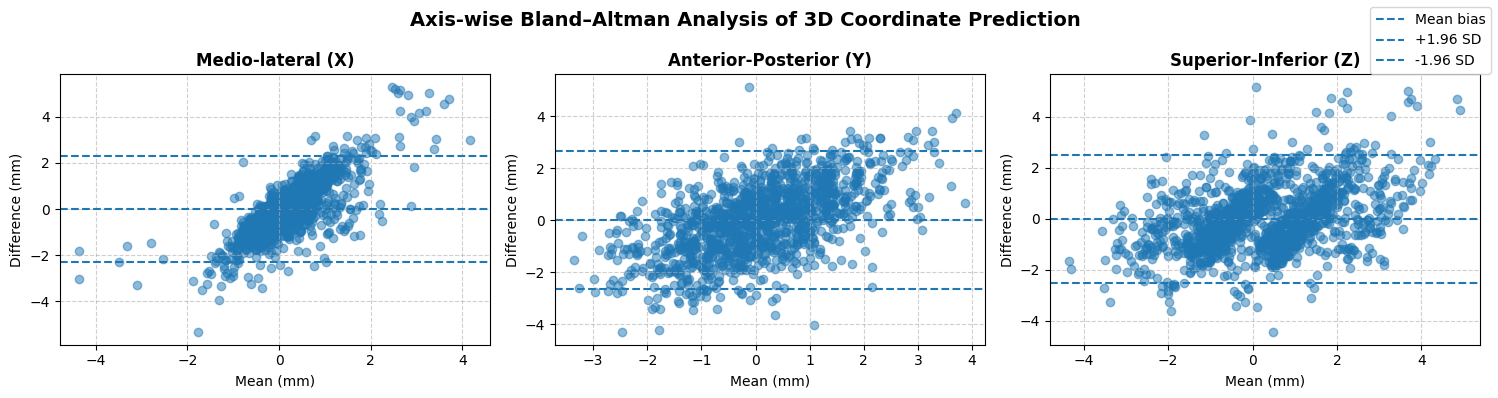

In [ ]:
# ============================================================
# CALLING FUNCTIONS
# ============================================================
plot_bland_altman_axes(y_true_all, y_pred_all)

In [ ]:
# ============================================================
# FUNCTION 2: EUCLIDEAN BLAND–ALTMAN
# ============================================================
def plot_bland_altman_euclidean(y_true_all, y_pred_all):

    # Convert to Euclidean distance
    euc_true = np.linalg.norm(y_true_all.values, axis=1)
    euc_pred = np.linalg.norm(y_pred_all, axis=1)

    mean = (euc_true + euc_pred) / 2
    diff = euc_true - euc_pred

    # ---- KEY STATS ----
    mean_diff = np.mean(diff)
    std_diff = np.std(diff)

    loa_upper = mean_diff + 1.96 * std_diff
    loa_lower = mean_diff - 1.96 * std_diff

    # ---- PRINT VALUES
    print(f"Mean Bias: {mean_diff:.3f} mm")
    print(f"Upper LoA (+1.96 SD): {loa_upper:.3f} mm")
    print(f"Lower LoA (-1.96 SD): {loa_lower:.3f} mm")

    # ---- PLOT ----
    plt.figure(figsize=(6, 5))
    plt.scatter(mean, diff, alpha=0.5)

    plt.axhline(mean_diff, linestyle='--', label=f'Mean bias ({mean_diff:.2f})')
    plt.axhline(loa_upper, linestyle='--', label=f'+1.96 SD ({loa_upper:.2f})')
    plt.axhline(loa_lower, linestyle='--', label=f'-1.96 SD ({loa_lower:.2f})')

    plt.title(
        "Bland–Altman Analysis of Euclidean Distance Prediction",
        fontweight='bold'
    )
    plt.xlabel("Mean Euclidean Distance (mm)")
    plt.ylabel("Difference (mm)")

    plt.grid(True, linestyle='--', alpha=0.6)
    plt.legend()
    plt.tight_layout()
    plt.show()

    return mean_diff, loa_lower, loa_upper


Mean Bias: 0.971 mm
Upper LoA (+1.96 SD): 3.331 mm
Lower LoA (-1.96 SD): -1.389 mm


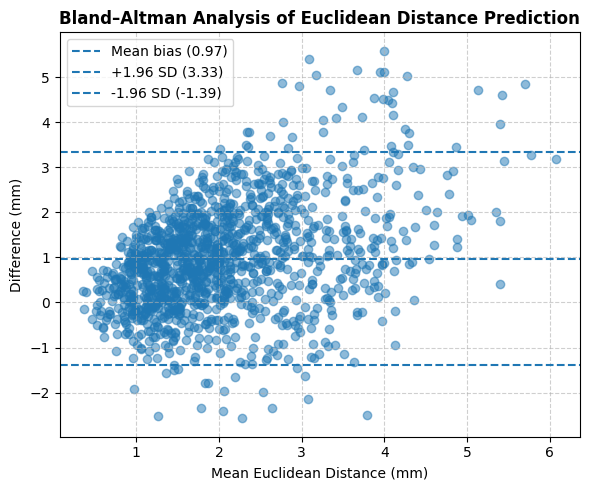

In [ ]:
mean_bias, loa_lower, loa_upper = plot_bland_altman_euclidean(y_true_all, y_pred_all)

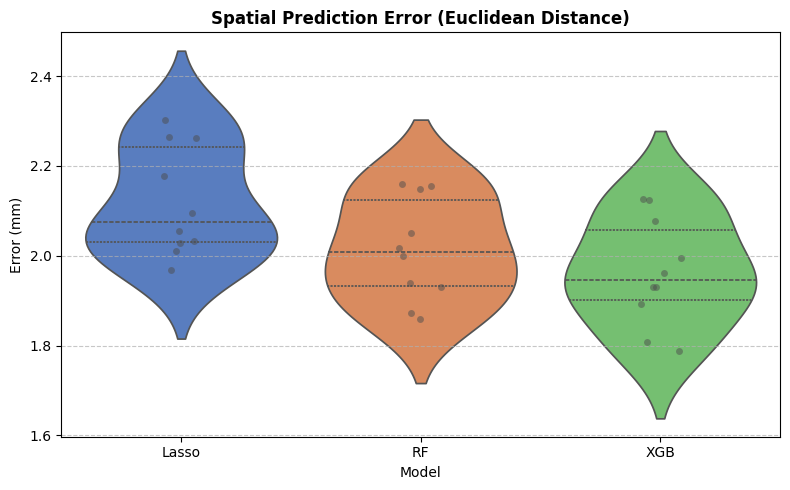

In [ ]:
# ============================================================
#  VIOLIN PLOT
# ============================================================
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df_melt = plot_df.melt(var_name='Model', value_name='Euc_Error')

plt.figure(figsize=(8, 5))

sns.violinplot(
    x='Model', y='Euc_Error',
    hue='Model',
    data=df_melt,
    inner="quartile",
    palette='muted',
    legend=False
)

sns.stripplot(
    x='Model', y='Euc_Error',
    data=df_melt,
    color=".3",
    alpha=0.5,
    jitter=True
)


plt.grid(axis='y', linestyle='--', alpha=0.7)

plt.title("Spatial Prediction Error (Euclidean Distance)", fontweight='bold')
plt.ylabel("Error (mm)")
plt.tight_layout()
plt.show()